# 09 · Seguimiento después del entrenamiento

**Objetivo:** comprobar el modelo con datos que llegaron **después** de entrenarlo, comparando cada previsión con el precio real cuando se conoce.

El test (notebook 07) ya hace esto a gran escala: las redes se entrenan con datos hasta el 31 de diciembre de 2023 y se comparan con lo que pasó de enero de 2024 a noviembre de 2026. Este notebook lo repite con los **modelos de la aplicación**, que se reentrenaron con todos los datos hasta el **3 de noviembre de 2026** (`app/modelos/modelos.json`):

1. Se descargan los datos nuevos, igual que con el botón *Actualizar datos* de la aplicación.
2. Cada día nuevo pasa por los modelos guardados **sin reentrenarlos** (`app_model.track`).
3. Cuando llega la fecha objetivo, la previsión se compara con el precio real y con el modelo ingenuo («el precio dentro de *h* días será el de hoy»).

> **Es una demostración, no una evaluación.** En dos semanas solo se cierran unas pocas previsiones a 1 semana, casi solapadas entre sí. La evidencia de si el modelo funciona son los casi tres años de test del notebook 07.

Para actualizarlo con los datos más recientes:

```bash
poetry run python -c "from oil_forecast.data import run_etl; run_etl()"
```

y volver a ejecutar el notebook.

In [1]:
import json

import matplotlib.pyplot as plt
import pandas as pd

from oil_forecast.app_model import APP_MODELS_DIR, track
from oil_forecast.experiment_log import H_LABELS
from oil_forecast.plotting import COLORS, INK_2, set_style
from oil_forecast.training import load_model_data

set_style()
data = load_model_data()
trained = json.loads((APP_MODELS_DIR / "modelos.json").read_text())
print(f"Modelos entrenados con datos hasta el {trained['ultimo_dato']}; datos disponibles hasta el {data.index[-1]:%Y-%m-%d}")

t = track(data=data)  # one row per origin and horizon, without retraining
t["Plazo"] = t.horizonte.map(H_LABELS)

Modelos entrenados con datos hasta el 2026-11-03; datos disponibles hasta el 2026-11-11


## 1. Previsiones a 1 semana

Una fila por día desde el último dato del entrenamiento. Las previsiones cuya fecha objetivo aún no está en los datos quedan pendientes (el precio del Brent de FRED se publica con unos días de retraso).

In [2]:
week = t[t.horizonte == "corto"].assign(
    Origen=lambda d: d.origen.dt.strftime("%d/%m/%Y"),
    Objetivo=lambda d: d.fecha_objetivo.dt.strftime("%d/%m/%Y"),
    **{"Intervalo 80 %": lambda d: d.apply(lambda r: f"{r.ic80_inferior:.2f} – {r.ic80_superior:.2f}", axis=1),
       "¿Dentro?": lambda d: d.dentro_ic80.map({True: "sí", False: "no"}).fillna("pendiente")},
)
(week.set_index("Origen")[["precio_hoy", "prevision", "Intervalo 80 %", "Objetivo", "precio_real",
                           "error_modelo", "error_ingenuo", "¿Dentro?"]]
 .rename(columns={"precio_hoy": "Precio ese día ($)", "prevision": "Previsión ($)", "precio_real": "Precio real ($)",
                  "error_modelo": "Error modelo ($)", "error_ingenuo": "Error ingenuo ($)"})
 .style.format(precision=2, na_rep="—"))

,Precio ese día ($),Previsión ($),Intervalo 80 %,Objetivo,Precio real ($),Error modelo ($),Error ingenuo ($),¿Dentro?
Origen,,,,,,,,
03/11/2026,107.03,106.25,94.15 – 118.70,10/11/2026,90.16,16.09,16.87,no
04/11/2026,91.84,91.15,77.84 – 105.31,11/11/2026,92.14,0.99,0.30,sí
05/11/2026,97.96,97.24,82.30 – 113.29,12/11/2026,—,—,—,pendiente
06/11/2026,97.83,97.10,82.42 – 112.81,13/11/2026,—,—,—,pendiente
09/11/2026,91.03,90.37,76.35 – 105.44,16/11/2026,—,—,—,pendiente
10/11/2026,90.16,89.49,75.63 – 104.38,17/11/2026,—,—,—,pendiente
11/11/2026,92.14,91.43,77.14 – 106.82,18/11/2026,—,—,—,pendiente


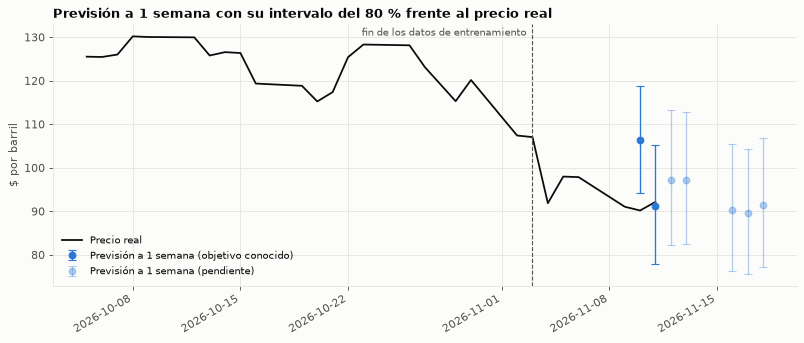

In [3]:
fig, ax = plt.subplots(figsize=(12, 4.8))
since = pd.Timestamp(trained["ultimo_dato"])
window = data.index >= since - pd.Timedelta(days=30)
ax.plot(data.index[window], data.price[window], color=COLORS["Real"], lw=1.6, label="Precio real")
ax.axvline(since, color=INK_2, ls="--", lw=1)
ax.text(since, ax.get_ylim()[1], "fin de los datos de entrenamiento  ", ha="right", va="top", fontsize=9, color=INK_2)
for known, marker, alpha, label in [(True, "o", 1.0, "Previsión a 1 semana (objetivo conocido)"),
                                    (False, "o", 0.35, "Previsión a 1 semana (pendiente)")]:
    w = week[week.objetivo_conocido == known]
    if w.empty:
        continue
    ax.errorbar(w.fecha_objetivo, w.prevision, yerr=[w.prevision - w.ic80_inferior, w.ic80_superior - w.prevision],
                fmt=marker, color=COLORS["LSTM"], alpha=alpha, capsize=4, lw=1.2, label=label)
ax.set_ylabel("$ por barril")
ax.set_title("Previsión a 1 semana con su intervalo del 80 % frente al precio real")
ax.legend(loc="lower left", fontsize=9)
fig.autofmt_xdate()
plt.show()

Cada punto azul está en la **fecha que se predice**, con su intervalo del 80 %; la línea negra es el precio real.

**Lectura con los datos hasta el 11 de noviembre de 2026:**

- **Previsión del 3 de noviembre** (precio de 107,03 $): 106,25 $ para el 10 de noviembre, con intervalo de 94,15 $ a 118,70 $. El precio real fue **90,16 $, fuera del intervalo**. El 4 de noviembre el Brent cayó un 14 % en un solo día, de 107 $ a 92 $, y ningún modelo lo anticipó: el error fue de 16,09 $, y el del ingenuo de 16,87 $.
- **Previsión del 4 de noviembre** (91,84 $, con la caída ya en los datos): 91,15 $ para el 11 de noviembre, con intervalo de 77,84 $ a 105,31 $. El precio real fue **92,14 $, dentro del intervalo**: error de 0,99 $, frente a 0,30 $ del ingenuo.
- En los dos casos la red queda prácticamente igual que el ingenuo, como en el test a 1 semana (RMSE 5,81 $ frente a 5,82 $). No anticipa un salto brusco, y se adapta en cuanto el salto entra en los datos, sin reentrenar.
- Una previsión de dos fuera de un intervalo del 80 % no permite sacar conclusiones sobre la cobertura. En el test, con unas 700 previsiones, el intervalo a 1 semana cubrió el 79 %.

## 2. Previsiones a 3 meses y a 1 año

Ninguna se puede comprobar todavía: la primera a 3 meses vence a finales de enero de 2027 y la primera a 1 año en octubre de 2027. La tabla deja apuntado lo que predijo el modelo para compararlo cuando lleguen esas fechas.

In [4]:
long = t[t.horizonte != "corto"]
(long.assign(Origen=long.origen.dt.strftime("%d/%m/%Y"), Objetivo=long.fecha_objetivo.dt.strftime("%d/%m/%Y"))
 .pivot_table(index="Origen", columns="Plazo", values="prevision", sort=False)
 .rename(columns=lambda c: f"Previsión a {c} ($)")
 .style.format(precision=2))

Plazo,Previsión a 3 meses ($),Previsión a 1 año ($)
Origen,,
03/11/2026,103.96,105.00
04/11/2026,88.81,91.41
05/11/2026,96.87,98.81
06/11/2026,95.50,99.53
09/11/2026,90.96,94.04
10/11/2026,90.65,94.25
11/11/2026,91.92,97.34


**Nota sobre las cifras de la aplicación.** El 3 de noviembre la aplicación guardó como previsión 106,24 $ a 1 semana, 104,45 $ a 3 meses y 105,16 $ a 1 año. Recalculadas aquí salen 106,25 $, 103,96 $ y 105,00 $. Los modelos son los mismos: la diferencia viene de que FRED y Yahoo Finance revisan algunos valores pasados al volver a descargarlos. Con los datos tal como estaban el 3 de noviembre, el cálculo reproduce exactamente las cifras de la aplicación.